# CS5489 Course Project — AI-Generated Content (AIGC) Localization

**Group Name:** Course Project Group 5  
**Members:** [Fill Canvas group member names before final upload]

## 1. Problem Statement & Experimental Protocol

Given an RGB photograph containing local AI-generated edits (object insertion, object removal, or inpainting), our goal is dense binary prediction: output a full-resolution 0/1 mask (`0`: authentic photographic pixel, `1`: AI-edited pixel) encoded as 1-based column-major RLE.

- **Strict Data Hygiene:** All experiments across Phases 1–7 use the **exact same fixed 4,500 train / 500 validation split** (`split.json`, seed `5489`). Public test images are strictly excluded from training, model selection, and threshold analysis.
- **Native-Resolution Evaluation:** While models are selected during training by grid-level validation `micro-IoU` at threshold `0.50`, all final comparisons are computed on the **500 original-resolution validation masks** across multiple metrics: `micro-IoU`, `mean image IoU`, `micro-Dice`, `mean image Dice`, `Precision`, `Recall`, `Pixel Accuracy`, `PR-AUC`, and five edited-area bins (`<1%` to `30–100%`).
- **Offline TA Compatibility:** The winning Phase 7 model uses only `torch` and `torchvision` (matching TA's reference environment), requires `< 450 MB` GPU VRAM during inference (compatible with RTX A1000 8 GB and CPU fallback), and loads completely offline (`pretrained=False`).

## 2. Full Experimental Progression (Phases 1–7 & Teammate Tier-0 Audit)

Phases 1–6 systematically diagnosed a randomly initialized 118K-parameter `SmallUNet` across loss weighting, input resolution (384), SRM high-pass filtering, patch-based cropping, and deeper 3-scale skip connections—all plateauing at `10.5%–14.1%` native micro-IoU (barely above the `13.07%` all-foreground baseline). A teammate's Tier-0 post-processing study pushed a CPU-reproduced Weighted BCE checkpoint from `12.92%` to `17.90%` by lowering the threshold to `0.35`, but at the cost of severe over-segmentation (`39.65%` predicted foreground vs `13.07%` ground truth) and collapsing `<5%` small-edit IoU by half.

**Phase 7 Hypothesis:** Replacing scratch-initialized tiny CNNs with ImageNet-1K pretrained hierarchical encoders at `512×512`, paired with matched geometric/photometric augmentation, a balanced `BCE + per-image Dice + micro-Dice` objective, and a parallel high-resolution spatial detail branch, should simultaneously unlock semantic consistency cues and sharp pixel-level boundaries.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

comp = pd.read_csv("phase_comparison.csv")
pct_cols = ["micro_iou", "mean_img_iou", "micro_dice", "precision", "recall", "pred_fg", "pix_acc", "pr_auc", "bin_<1%", "bin_1-5%", "bin_30-100%"]
styled = comp[["stage"] + pct_cols].copy()
for c in pct_cols:
    styled[c] = styled[c].map(lambda v: f"{v:.2%}" if pd.notna(v) else "—")
display(styled)

,stage,micro_iou,mean_img_iou,micro_dice,precision,recall,pred_fg,pix_acc,pr_auc,bin_<1%,bin_1-5%,bin_30-100%
0,All-Foreground Baseline,13.07%,12.31%,23.12%,13.07%,100.00%,100.00%,13.07%,—,0.53%,2.72%,55.37%
1,Phase 1: V1 SmallUNet 256 (0.50),13.36%,14.30%,23.58%,37.63%,17.16%,5.96%,85.46%,24.48%,2.54%,15.30%,11.10%
2,Phase 2: Weighted BCE 256 (0.50),14.05%,14.39%,24.64%,27.66%,22.22%,10.50%,82.24%,22.85%,1.98%,10.44%,14.18%
3,Phase 3: V1 SmallUNet 384 (0.50),13.20%,14.91%,23.33%,37.82%,16.87%,5.83%,85.51%,22.85%,2.61%,15.31%,10.80%
4,Phase 4: RGB+SRM SmallUNet 256 (0.50),11.35%,12.60%,20.39%,—,—,—,—,—,—,—,—
5,Phase 5B: Mask-Aware Crop (0.50),10.51%,11.75%,19.01%,40.52%,12.42%,4.01%,—,20.02%,—,—,—
6,Phase 6: 3-Scale UNet 256 (0.50),11.45%,12.97%,20.55%,38.84%,13.97%,4.70%,—,24.57%,2.31%,12.47%,8.59%
7,"Teammate Tier-0 (CPU Weighted, 0.35+TTA+fill)",17.90%,15.48%,30.36%,20.19%,61.24%,39.65%,63.29%,22.57%,1.05%,4.98%,44.31%
8,Phase 7A: ResNet34-UNet 512 (Base@0.50),44.60%,41.94%,61.69%,73.60%,53.09%,9.43%,91.38%,69.24%,10.61%,31.06%,44.33%
9,Phase 7A: ResNet34-UNet 512 (TTA@0.50),45.23%,42.09%,62.29%,76.80%,52.39%,8.92%,91.71%,70.18%,11.89%,31.34%,43.54%


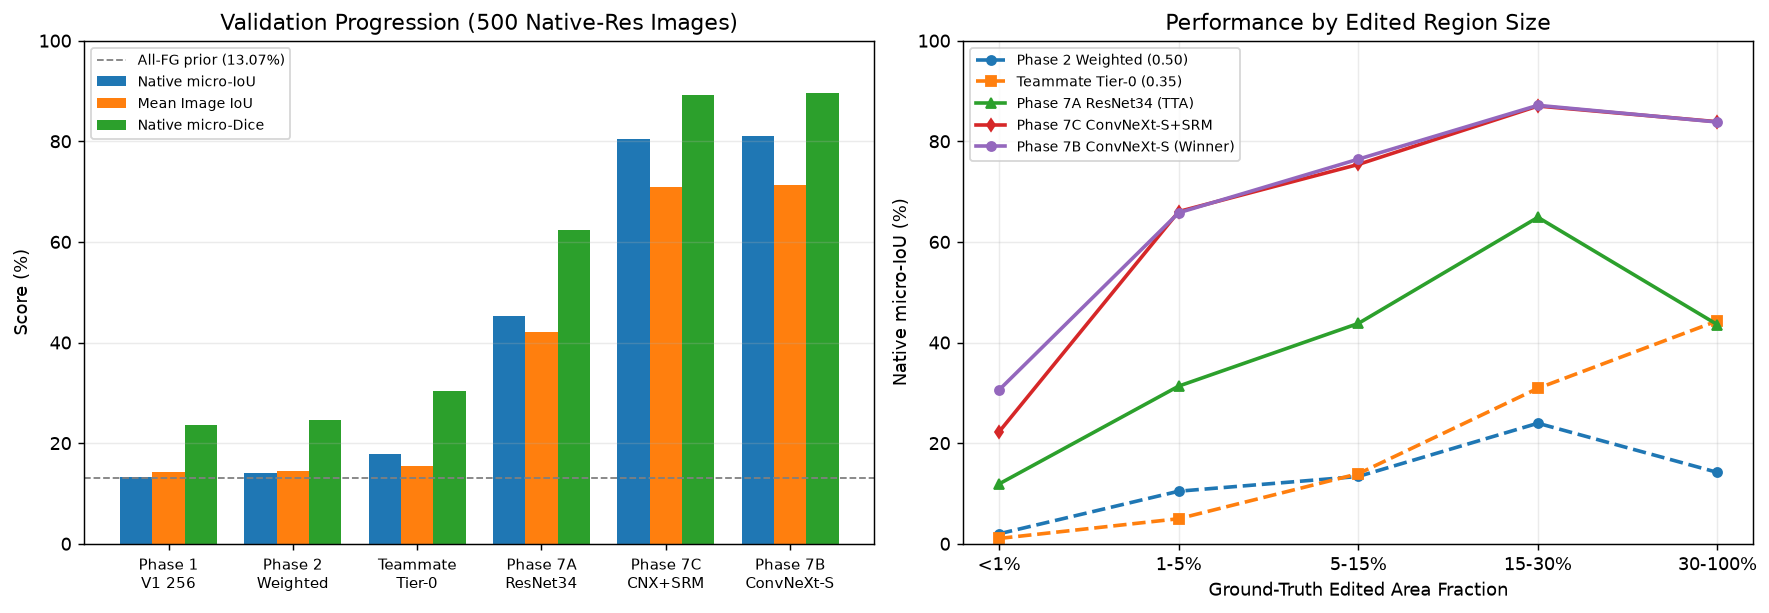

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), layout="constrained")
pick = [
    ("Phase 1\nV1 256", 0.1336, 0.1430, 0.2358),
    ("Phase 2\nWeighted", 0.1405, 0.1439, 0.2464),
    ("Teammate\nTier-0", 0.1790, 0.1548, 0.3037),
    ("Phase 7A\nResNet34", 0.4523, 0.4209, 0.6229),
    ("Phase 7C\nCNX+SRM", 0.8051, 0.7092, 0.8920),
    ("Phase 7B\nConvNeXt-S", 0.8101, 0.7137, 0.8951),
]
x = np.arange(len(pick))
w = 0.26
axes[0].bar(x - w, [p[1] * 100 for p in pick], w, label="Native micro-IoU")
axes[0].bar(x, [p[2] * 100 for p in pick], w, label="Mean Image IoU")
axes[0].bar(x + w, [p[3] * 100 for p in pick], w, label="Native micro-Dice")
axes[0].axhline(13.07, color="gray", linestyle="--", linewidth=1, label="All-FG prior (13.07%)")
axes[0].set_xticks(x)
axes[0].set_xticklabels([p[0] for p in pick], fontsize=8.5)
axes[0].set(ylabel="Score (%)", ylim=(0, 100), title="Validation Progression (500 Native-Res Images)")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.25)

bins = ["<1%", "1-5%", "5-15%", "15-30%", "30-100%"]
bx = np.arange(len(bins))
for label, row_name, style in [
    ("Phase 2 Weighted (0.50)", "Phase 2: Weighted BCE 256 (0.50)", "o--"),
    ("Teammate Tier-0 (0.35)", "Teammate Tier-0 (CPU Weighted, 0.35+TTA+fill)", "s--"),
    ("Phase 7A ResNet34 (TTA)", "Phase 7A: ResNet34-UNet 512 (TTA@0.50)", "^-"),
    ("Phase 7C ConvNeXt-S+SRM", "Phase 7C: ConvNeXt-Small+SRM Detail-UNet 512 (TTA@0.50)", "d-"),
    ("Phase 7B ConvNeXt-S (Winner)", "Phase 7B: ConvNeXt-Small Detail-UNet 512 (TTA@0.50)", "o-"),
]:
    r = comp.loc[comp["stage"] == row_name].iloc[0]
    axes[1].plot(bx, [r[f"bin_{b}"] * 100 for b in bins], style, linewidth=2, markersize=5, label=label)
axes[1].set_xticks(bx)
axes[1].set_xticklabels(bins)
axes[1].set(xlabel="Ground-Truth Edited Area Fraction", ylabel="Native micro-IoU (%)", ylim=(0, 100), title="Performance by Edited Region Size")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)
plt.show()

## 3. Winning Candidate Training Dynamics & Threshold Calibration (Phase 7B)

**Architecture (`ConvNeXt-Small Detail-UNet`):**
- Pretrained `torchvision.models.convnext_small` (`IMAGENET1K_V1`, 7×7 depthwise convs + LayerNorm, strides 4/8/16/32).
- **High-Resolution Spatial Detail Stem:** Two parallel convolutional stages at stride 1 (24 ch) and stride 2 (48 ch) fused directly into the final U-Net decoder stages so small-edit boundaries are preserved despite ConvNeXt's stride-4 patchify stem.
- **Training Recipe:** `512×512` input, AdamW (`backbone_lr=1e-4`, `decoder_lr=5e-4`, `weight_decay=2e-2`), 2-epoch warmup + cosine schedule for 25 epochs, `bfloat16` AMP, horizontal flip + random resized crop + mild color jitter.

**Controlled SRM Ablation (Exp 7B vs 7C):** Adding fixed 5×5 SRM high-pass residual filters to the detail stem slightly decreased native micro-IoU (`81.01% → 80.51%`) and hurt `<1%` small edits (`30.58% → 22.25%`), confirming that at `512×512` resized input, learned multi-scale RGB features outperform fixed high-pass filters.

Architecture: convnext_small_unet (53,665,065 params), input=512x512
Best epoch: 25/25 | 512-grid micro-IoU: 80.27% | Train time: 1429.4s
Native 500-img (TTA@0.50): micro-IoU=81.01%, mean-img IoU=71.37%, micro-Dice=89.51%, Precision=94.66%, Recall=84.89%, PR-AUC=94.60%
5-fold OOF CV (TTA): chosen=[0.45, 0.45, 0.35, 0.4, 0.4], OOF micro-IoU=81.14% (vs fixed 0.50: 81.01%)
TA hardware probe: ckpt=204.82 MB, peak inference VRAM=428.16 MB, CPU TTA=587.2 ms/img


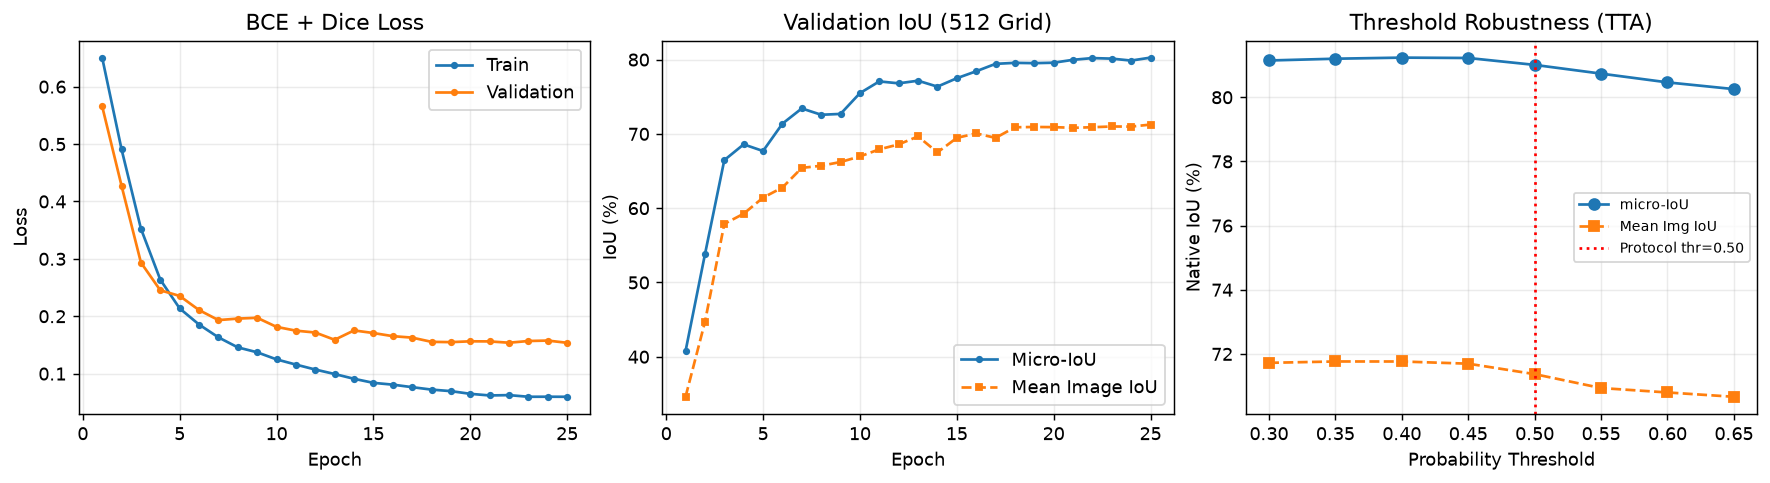

In [3]:
config = json.loads(Path("config.json").read_text(encoding="utf-8"))
history = pd.read_csv("training_history.csv")
train_sum = json.loads(Path("training_summary.json").read_text(encoding="utf-8"))
val_sum = json.loads(Path("validation_summary.json").read_text(encoding="utf-8"))
ta_probe = json.loads(Path("ta_compatibility_probe.json").read_text(encoding="utf-8"))

print(f"Architecture: {config['arch']} ({config['parameters']:,} params), input={config['input_size']}x{config['input_size']}")
print(f"Best epoch: {train_sum['best_epoch']}/{config['epochs']} | 512-grid micro-IoU: {train_sum['best_val_micro_iou_512']:.2%} | Train time: {train_sum['training_seconds']:.1f}s")
t = val_sum['tta_050']
print(f"Native 500-img (TTA@0.50): micro-IoU={t['micro_iou']:.2%}, mean-img IoU={t['mean_img_iou']:.2%}, micro-Dice={t['micro_dice']:.2%}, Precision={t['precision']:.2%}, Recall={t['recall']:.2%}, PR-AUC={val_sum['pr_auc_grid_tta']:.2%}")
print(f"5-fold OOF CV (TTA): chosen={val_sum['oof_cv']['tta']['chosen_thrs']}, OOF micro-IoU={val_sum['oof_cv']['tta']['micro_iou']:.2%} (vs fixed 0.50: {t['micro_iou']:.2%})")
print(f"TA hardware probe: ckpt={ta_probe['checkpoint_mb']} MB, peak inference VRAM={ta_probe['inference_peak_vram_mb']} MB, CPU TTA={ta_probe['cpu_tta_ms_per_image']} ms/img")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6), layout="constrained")
axes[0].plot(history.epoch, history.train_loss, "o-", ms=3, label="Train")
axes[0].plot(history.epoch, history.val_loss, "o-", ms=3, label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Loss", title="BCE + Dice Loss")
axes[0].legend(); axes[0].grid(alpha=0.25)

axes[1].plot(history.epoch, history.val_micro_iou * 100, "o-", ms=3, label="Micro-IoU")
axes[1].plot(history.epoch, history.val_mean_img_iou * 100, "s--", ms=3, label="Mean Image IoU")
axes[1].set(xlabel="Epoch", ylabel="IoU (%)", title="Validation IoU (512 Grid)")
axes[1].legend(); axes[1].grid(alpha=0.25)

sweep = pd.read_csv("threshold_sweep.csv")
sw_tta = sweep[sweep["mode"] == "tta"]
axes[2].plot(sw_tta.threshold, sw_tta.micro_iou * 100, "o-", label="micro-IoU")
axes[2].plot(sw_tta.threshold, sw_tta.mean_img_iou * 100, "s--", label="Mean Img IoU")
axes[2].axvline(0.50, color="red", linestyle=":", label="Protocol thr=0.50")
axes[2].set(xlabel="Probability Threshold", ylabel="Native IoU (%)", title="Threshold Robustness (TTA)")
axes[2].legend(fontsize=8); axes[2].grid(alpha=0.25)
plt.show()

## 4. Per-Image Distribution & Failure Analysis

Understanding *where* the model succeeds and fails is essential:
- **High precision & sharp localization:** Across the 500 validation images, **median per-image IoU is 87.32%**, **316/500 images (63.2%) exceed 0.80 IoU**, and **388/500 (77.6%) exceed 0.50 IoU**. Even on `<1%` ultra-small edits, clearly visible edits such as `004048` (`0.57%` area) achieve `96.22%` IoU.
- **Primary failure mode (70/500 images with IoU < 0.20):** The failure subset has a median edited area of **`1.29%`** (4× smaller than the overall validation median of `5.22%`), with `28/70` below `1%` area and `54/70` (`77%`) being misses/under-predictions (`31` empty predictions, `18` wrong-region false alarms). Representative failures include ultra-small edits (`004657`, `0.32%`; `003703`, `0.60%`) and subtle seamless background removal (`002578`, `6.42%`), where `512×512` downsampling attenuates fine-grained boundary/texture cues.

Failure analysis summary: {
  "total_val": 500,
  "iou_ge_080": 316,
  "iou_ge_050": 388,
  "iou_lt_020": 70,
  "low_iou_median_target_frac": 0.01290294792715195,
  "all_val_median_target_frac": 0.0521984135298882,
  "low_iou_under_1pct_count": 28,
  "low_iou_empty_pred_count": 31,
  "low_iou_false_alarm_only_count": 18,
  "low_iou_underpredict_count": 54,
  "low_iou_overpredict_count": 12
}
Worst 10 validation failure cases:


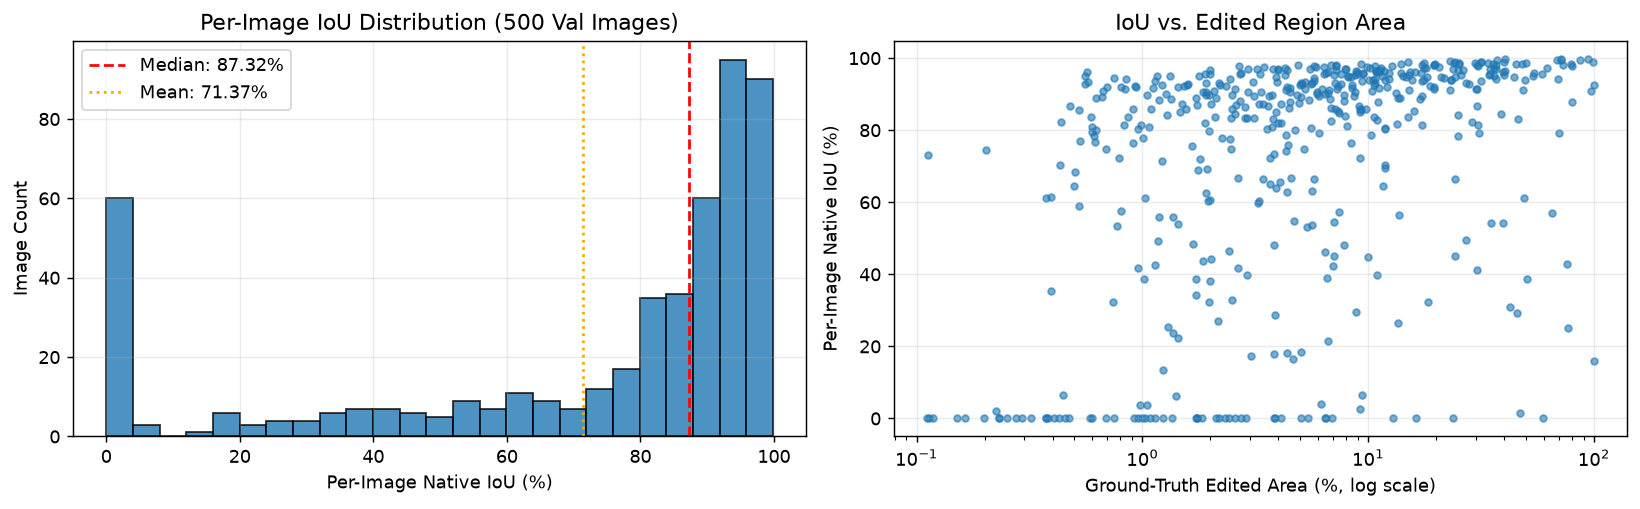

,ID,target_fraction,predicted_fraction,iou,dice,TP,FP,FN
468,003724,0.001506,0.012471,0.0,0.0,0,78336,9457
470,002578,0.064193,0.000000,0.0,0.0,0,0,1056053
35,001545,0.001139,0.009489,0.0,0.0,0,18219,2186
451,003173,0.002316,0.025052,0.0,0.0,0,48100,4446
39,002867,0.021931,0.000000,0.0,0.0,0,0,84906
438,003703,0.005976,0.000000,0.0,0.0,0,0,11473
427,002534,0.018286,0.000000,0.0,0.0,0,0,39541
69,004657,0.003203,0.000000,0.0,0.0,0,0,19417
408,003552,0.038805,0.000000,0.0,0.0,0,0,30175
411,000558,0.038442,0.000000,0.0,0.0,0,0,161239


In [4]:
by_img = pd.read_csv("validation_by_image.csv", dtype={"ID": str})
fail = json.loads(Path("failure_analysis.json").read_text(encoding="utf-8"))
print("Failure analysis summary:", json.dumps(fail, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), layout="constrained")
axes[0].hist(by_img["iou"] * 100, bins=25, edgecolor="black", alpha=0.8)
axes[0].axvline(by_img["iou"].median() * 100, color="red", linestyle="--", label=f"Median: {by_img['iou'].median():.2%}")
axes[0].axvline(by_img["iou"].mean() * 100, color="orange", linestyle=":", label=f"Mean: {by_img['iou'].mean():.2%}")
axes[0].set(xlabel="Per-Image Native IoU (%)", ylabel="Image Count", title="Per-Image IoU Distribution (500 Val Images)")
axes[0].legend(); axes[0].grid(alpha=0.25)

axes[1].scatter(by_img["target_fraction"] * 100, by_img["iou"] * 100, s=14, alpha=0.6)
axes[1].set_xscale("log")
axes[1].set(xlabel="Ground-Truth Edited Area (%, log scale)", ylabel="Per-Image Native IoU (%)", title="IoU vs. Edited Region Area")
axes[1].grid(alpha=0.25)
plt.show()

print("Worst 10 validation failure cases:")
display(by_img.sort_values("iou").head(10)[["ID", "target_fraction", "predicted_fraction", "iou", "dice", "TP", "FP", "FN"]])

## 5. Reproducible Training Pipeline

The full model definition (`models.py`), cache builder (`prepare_cache.py`), training script (`train_phase7.py`), and native-resolution evaluator (`evaluate_phase7.py`) are bundled beside this notebook. Set `RETRAIN = True` and point `ARCHIVE` to `AIGC Detection Dataset 2026.zip` to reproduce training end-to-end into `reproduction/model.pth` without overwriting the frozen submission artifacts.

In [5]:
import subprocess
import sys

RETRAIN = False
ARCHIVE = Path("AIGC Detection Dataset 2026.zip")
if RETRAIN:
    subprocess.run([sys.executable, "prepare_cache.py", "--archive", str(ARCHIVE), "--out", "cache512", "--size", "512"], check=True)
    subprocess.run([
        sys.executable, "train_phase7.py",
        "--arch", "convnext_small_unet",
        "--cache", "cache512",
        "--split", "split.json",
        "--out", "reproduction",
        "--ckpt-dir", "reproduction",
        "--epochs", "25", "--batch-size", "16", "--lr", "1e-4", "--weight-decay", "2e-2",
    ], check=True)
    subprocess.run([
        sys.executable, "evaluate_phase7.py",
        "--ckpt", "reproduction/model.pth",
        "--archive", str(ARCHIVE),
        "--split", "split.json",
        "--out", "reproduction",
    ], check=True)
else:
    print("RETRAIN is False; displaying verified archived outputs from the frozen Phase 7B run.")

RETRAIN is False; displaying verified archived outputs from the frozen Phase 7B run.
